In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/retail_store_inventory-selected-columns.csv"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
print("Number of rows and columns:", df.shape)
display(df.head())

Number of rows and columns: (73100, 10)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64


In [3]:
print(df.columns.tolist())


['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price']


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             73100 non-null  str    
 1   Store ID         73100 non-null  str    
 2   Product ID       73100 non-null  str    
 3   Category         73100 non-null  str    
 4   Region           73100 non-null  str    
 5   Inventory Level  73100 non-null  int64  
 6   Units Sold       73100 non-null  int64  
 7   Units Ordered    73100 non-null  int64  
 8   Demand Forecast  73100 non-null  float64
 9   Price            73100 non-null  float64
dtypes: float64(2), int64(3), str(5)
memory usage: 5.6 MB


In [5]:
print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
Date               0
Store ID           0
Product ID         0
Category           0
Region             0
Inventory Level    0
Units Sold         0
Units Ordered      0
Demand Forecast    0
Price              0
dtype: int64


In [6]:
print("Duplicate rows:", df.duplicated().sum())
display(df.describe())


Duplicate rows: 0


,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108
std,129.949514,108.919406,52.277448,109.254076,26.021945
min,50.000000,0.000000,20.000000,-9.990000,10.000000
25%,162.000000,49.000000,65.000000,53.670000,32.650000
50%,273.000000,107.000000,110.000000,113.015000,55.050000
75%,387.000000,203.000000,155.000000,208.052500,77.860000
max,500.000000,499.000000,200.000000,518.550000,100.000000


In [7]:
print("Unique products:", df["Product ID"].nunique())
print("Unique stores:", df["Store ID"].nunique())

print("Minimum price:", df["Price"].min())
print("Maximum price:", df["Price"].max())

print("Minimum units sold:", df["Units Sold"].min())
print("Maximum units sold:", df["Units Sold"].max())

Unique products: 20
Unique stores: 5
Minimum price: 10.0
Maximum price: 100.0
Minimum units sold: 0
Maximum units sold: 499


In [8]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())
print("Invalid dates:", df["Date"].isna().sum())

Earliest date: 2022-01-01 00:00:00
Latest date: 2024-01-01 00:00:00
Invalid dates: 0


In [9]:
df["Day_of_Week"] = df["Date"].dt.day_name()

display(df[["Date", "Day_of_Week"]].head())

,Date,Day_of_Week
0,2022-01-01,Saturday
1,2022-01-01,Saturday
2,2022-01-01,Saturday
3,2022-01-01,Saturday
4,2022-01-01,Saturday


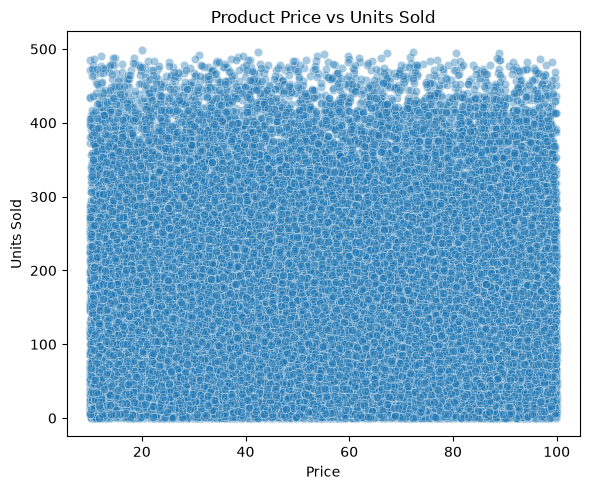

In [14]:
plt.figure(figsize=(6, 5))

sns.scatterplot(
    data=df,
    x="Price",
    y="Units Sold",
    alpha=0.4
)

plt.title("Product Price vs Units Sold")
plt.xlabel("Price")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()